In [2]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
train_df = pd.read_csv(
    r"D:\Mobile-Price-Range-Classification\data\raw\train.csv"
)
train_df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
# Step 3: Check dataset dimensions

print("Number of rows:", train_df.shape[0])
print("Number of columns:", train_df.shape[1])

Number of rows: 2000
Number of columns: 21


In [5]:
# Step 4: Display all column names

print("Dataset Columns:")

for column in train_df.columns:
    print(column)

Dataset Columns:
battery_power
blue
clock_speed
dual_sim
fc
four_g
int_memory
m_dep
mobile_wt
n_cores
pc
px_height
px_width
ram
sc_h
sc_w
talk_time
three_g
touch_screen
wifi
price_range


In [6]:
# Step 5: Check data types

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

In [7]:
# Step 6: Check missing values

missing_values = train_df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

Total Missing Values: 0


In [8]:
# Check duplicate rows
duplicates = train_df.duplicated().sum()
print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 0


In [9]:
# Statistical summary of numerical columns
train_df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,9.916500,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,6.064315,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,0.000000,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,5.000000,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,10.000000,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,15.000000,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,20.000000,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [10]:
# Count mobile phones in each price category

print(train_df["price_range"].value_counts().sort_index())

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


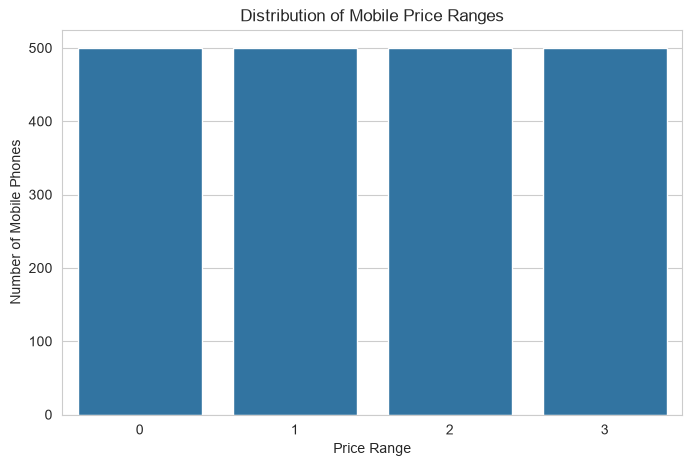

In [11]:
# Visualize the price range distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="price_range")

plt.title("Distribution of Mobile Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("Number of Mobile Phones")

plt.show()

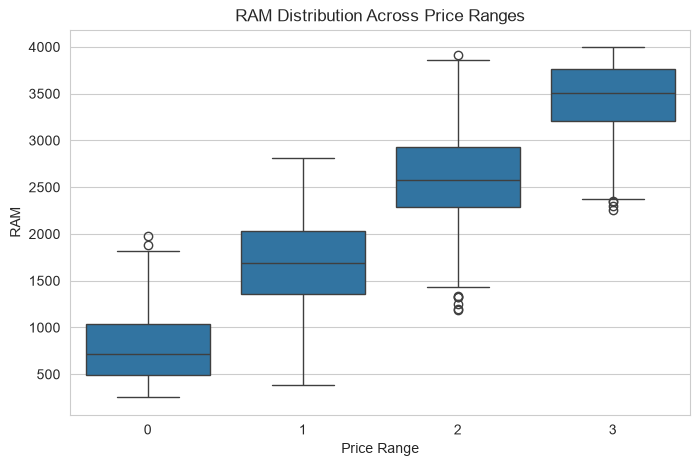

In [12]:
# RAM distribution by price range

plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="price_range", y="ram")

plt.title("RAM Distribution Across Price Ranges")
plt.xlabel("Price Range")
plt.ylabel("RAM")

plt.show()

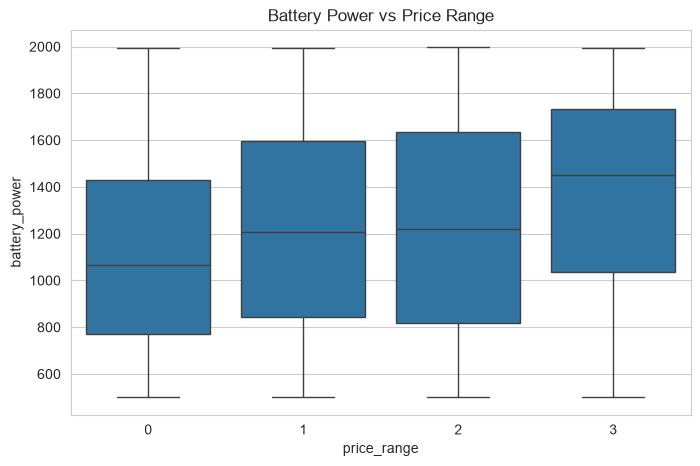

In [13]:
# Battery power distribution by price range

plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="price_range", y="battery_power")

plt.title("Battery Power vs Price Range")
plt.show()

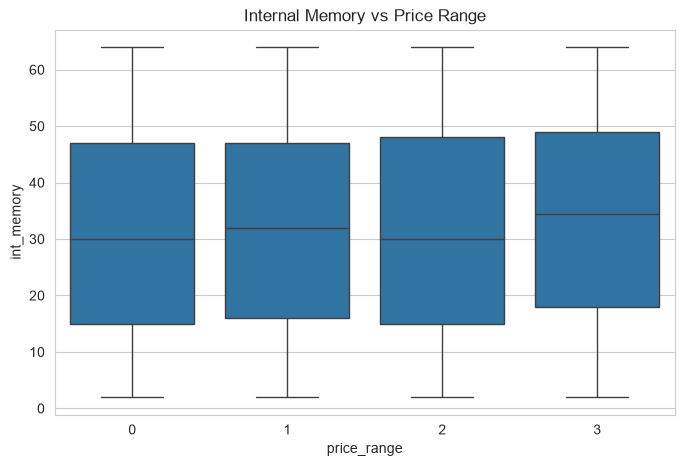

In [14]:
# Internal memory distribution

plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="price_range", y="int_memory")

plt.title("Internal Memory vs Price Range")
plt.show()

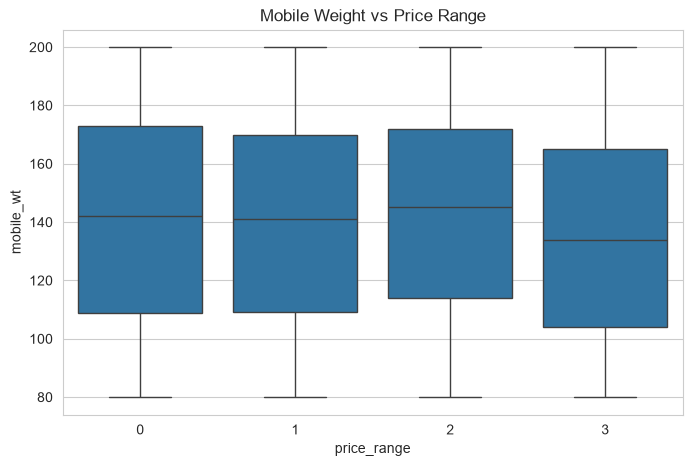

In [15]:
# Mobile weight distribution

plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="price_range", y="mobile_wt")

plt.title("Mobile Weight vs Price Range")
plt.show()

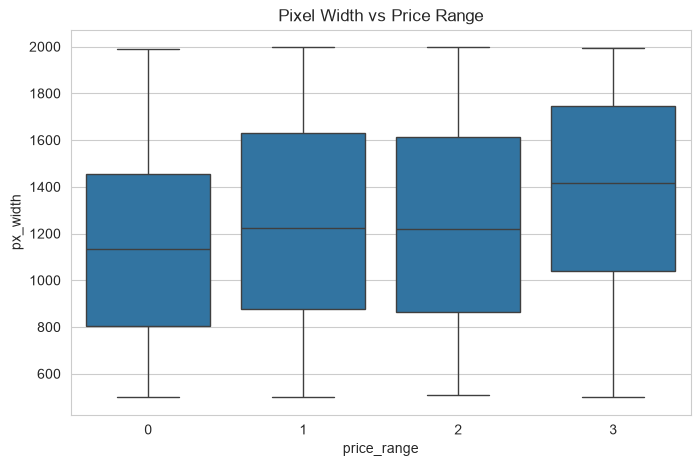

In [16]:
# Pixel width distribution

plt.figure(figsize=(8, 5))

sns.boxplot(data=train_df, x="price_range", y="px_width")

plt.title("Pixel Width vs Price Range")
plt.show()

In [17]:
# Step 23: Calculate correlation

correlation = train_df.corr()

correlation.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
battery_power,1.000000,0.011252,0.011482,-0.041847,0.033334,0.015665,-0.004004,0.034085,0.001844,-0.029727,0.031441,0.014901,-0.008402,-0.000653,-0.029959,-0.021421,0.052510,0.011522,-0.010516,-0.008343,0.200723
blue,0.011252,1.000000,0.021419,0.035198,0.003593,0.013443,0.041177,0.004049,-0.008605,0.036161,-0.009952,-0.006872,-0.041533,0.026351,-0.002952,0.000613,0.013934,-0.030236,0.010061,-0.021863,0.020573
clock_speed,0.011482,0.021419,1.000000,-0.001315,-0.000434,-0.043073,0.006545,-0.014364,0.012350,-0.005724,-0.005245,-0.014523,-0.009476,0.003443,-0.029078,-0.007378,-0.011432,-0.046433,0.019756,-0.024471,-0.006606
dual_sim,-0.041847,0.035198,-0.001315,1.000000,-0.029123,0.003187,-0.015679,-0.022142,-0.008979,-0.024658,-0.017143,-0.020875,0.014291,0.041072,-0.011949,-0.016666,-0.039404,-0.014008,-0.017117,0.022740,0.017444
fc,0.033334,0.003593,-0.000434,-0.029123,1.000000,-0.016560,-0.029133,-0.001791,0.023618,-0.013356,0.644595,-0.009990,-0.005176,0.015099,-0.011014,-0.012373,-0.006829,0.001793,-0.014828,0.020085,0.021998


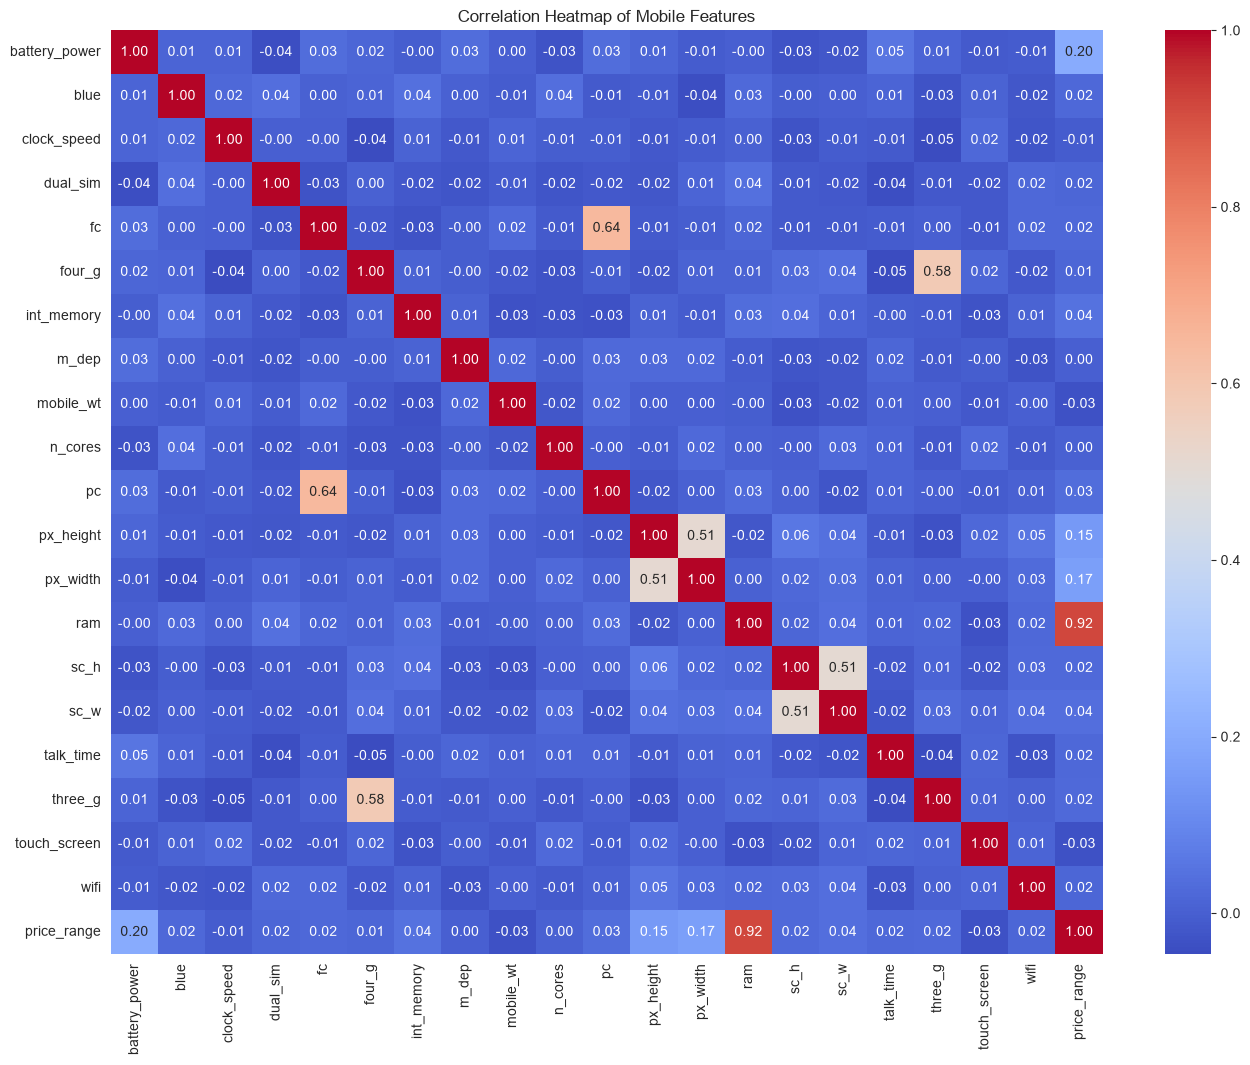

In [18]:
# Step 24: Correlation heatmap

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Mobile Features")
plt.show()

In [19]:
# Step 25: Correlation with target variable

price_correlation = correlation["price_range"].sort_values(
    ascending=False
)

print(price_correlation)

price_range      1.000000
ram              0.917046
battery_power    0.200723
px_width         0.165818
px_height        0.148858
int_memory       0.044435
sc_w             0.038711
pc               0.033599
three_g          0.023611
sc_h             0.022986
fc               0.021998
talk_time        0.021859
blue             0.020573
wifi             0.018785
dual_sim         0.017444
four_g           0.014772
n_cores          0.004399
m_dep            0.000853
clock_speed     -0.006606
mobile_wt       -0.030302
touch_screen    -0.030411
Name: price_range, dtype: float64


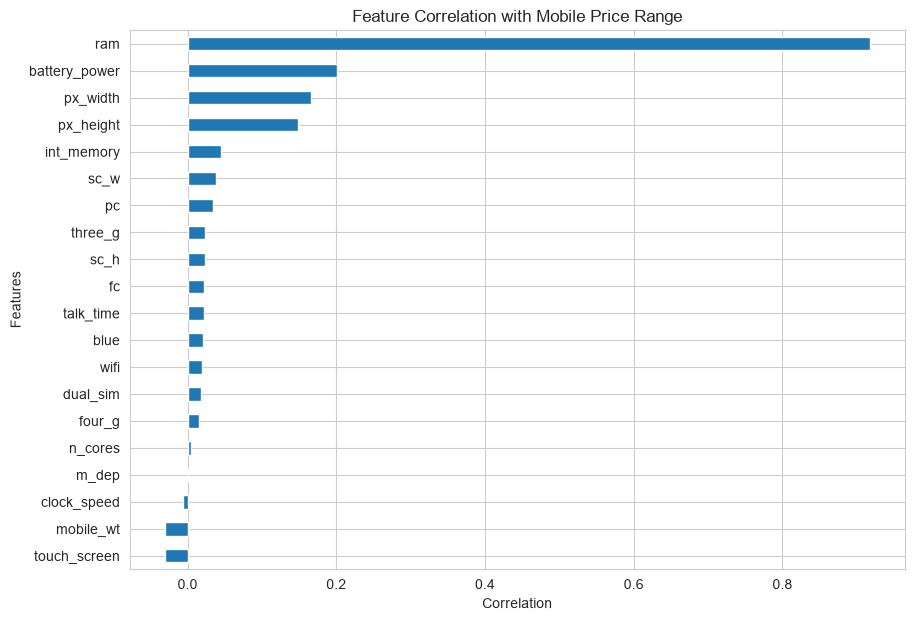

In [20]:
# Step 26: Visualize feature correlations with price

price_correlation.drop("price_range").sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Feature Correlation with Mobile Price Range")
plt.xlabel("Correlation")
plt.ylabel("Features")
plt.show()

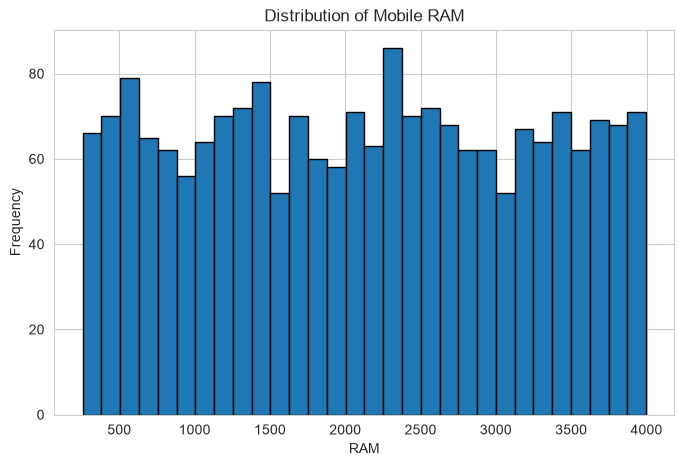

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(train_df["ram"], bins=30, edgecolor="black")

plt.title("Distribution of Mobile RAM")
plt.xlabel("RAM")
plt.ylabel("Frequency")

plt.show()

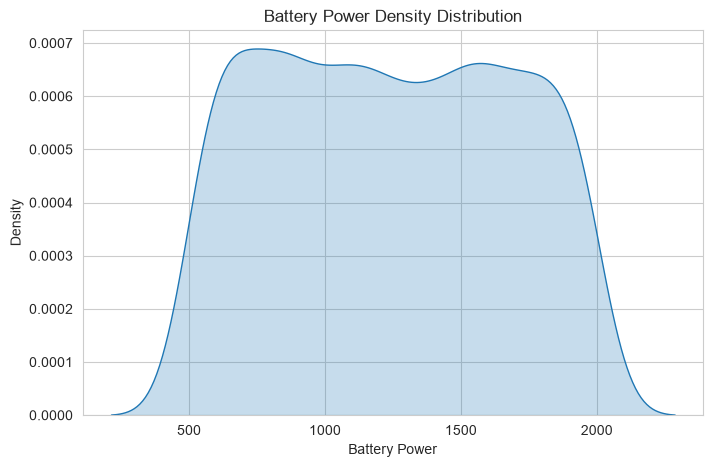

In [22]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=train_df, x="battery_power", fill=True)

plt.title("Battery Power Density Distribution")
plt.xlabel("Battery Power")

plt.show()

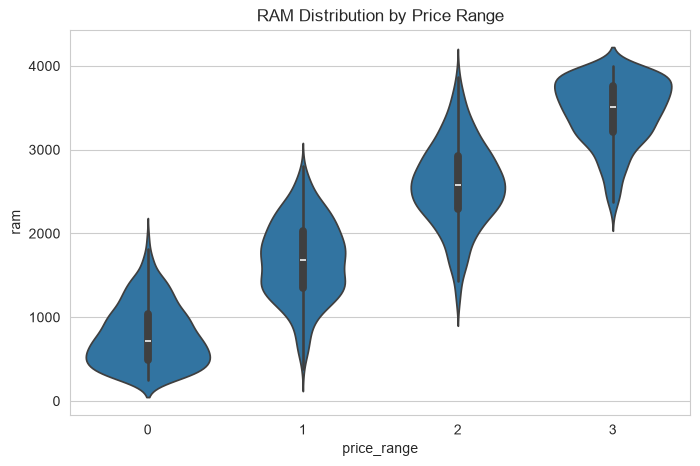

In [23]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=train_df, x="price_range", y="ram")

plt.title("RAM Distribution by Price Range")
plt.show()

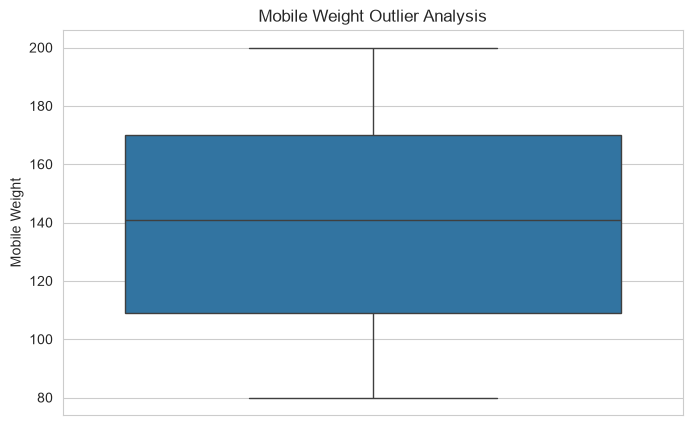

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=train_df["mobile_wt"])

plt.title("Mobile Weight Outlier Analysis")
plt.ylabel("Mobile Weight")

plt.show()

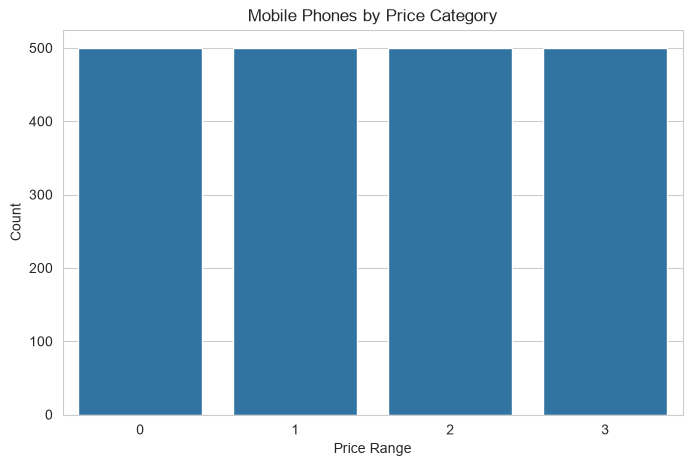

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="price_range")

plt.title("Mobile Phones by Price Category")
plt.xlabel("Price Range")
plt.ylabel("Count")

plt.show()

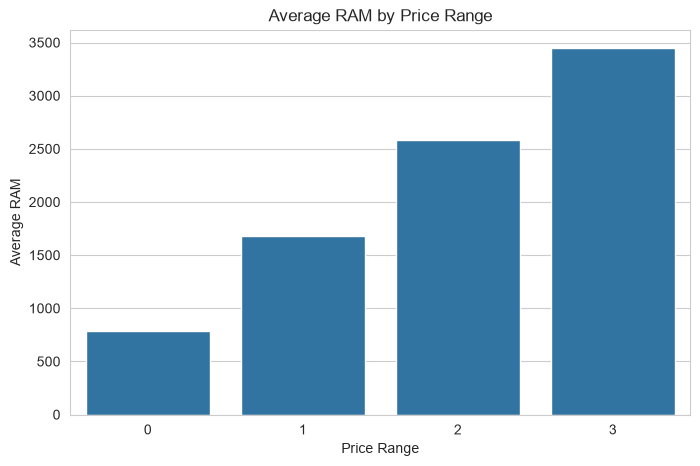

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(data=train_df, x="price_range", y="ram", errorbar=None)

plt.title("Average RAM by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average RAM")

plt.show()

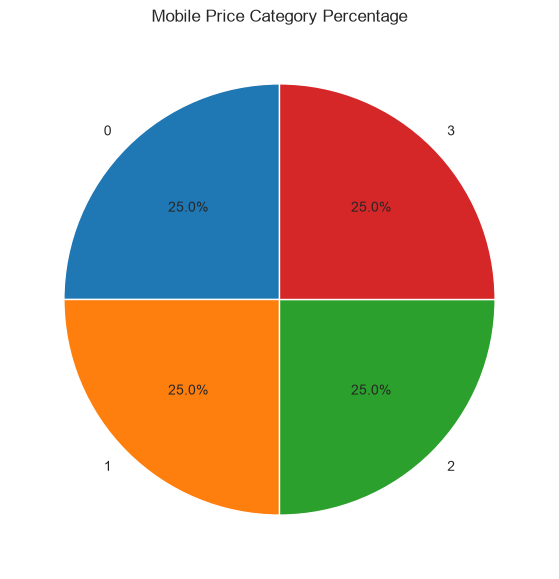

In [27]:
price_counts = train_df["price_range"].value_counts().sort_index()

plt.figure(figsize=(7, 7))

plt.pie(
    price_counts,
    labels=price_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Mobile Price Category Percentage")
plt.show()

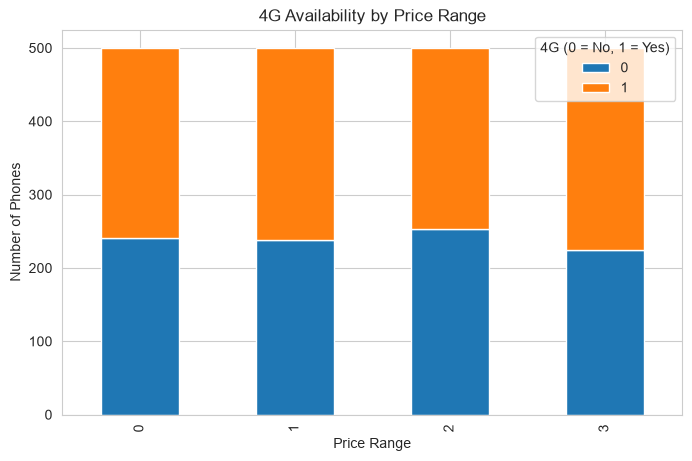

In [28]:
four_g_data = pd.crosstab(
    train_df["price_range"],
    train_df["four_g"]
)

four_g_data.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("4G Availability by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Phones")
plt.legend(title="4G (0 = No, 1 = Yes)")

plt.show()

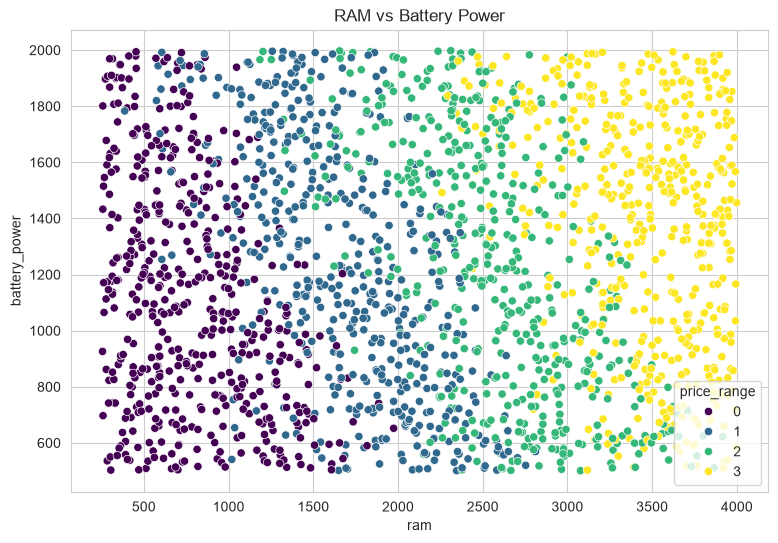

In [29]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=train_df,
    x="ram",
    y="battery_power",
    hue="price_range",
    palette="viridis"
)

plt.title("RAM vs Battery Power")
plt.show()

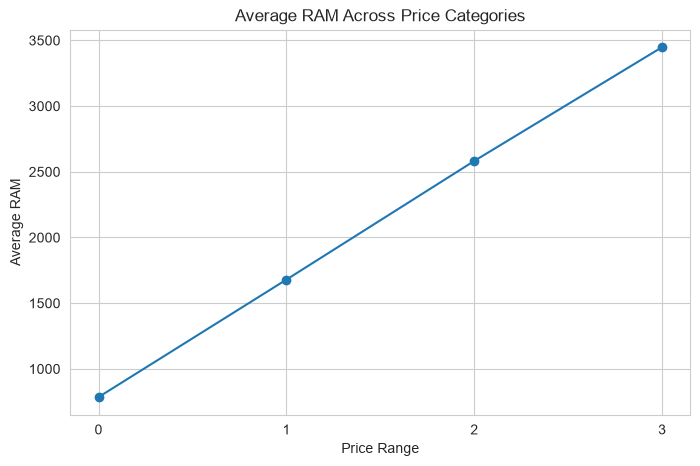

In [30]:
avg_ram = train_df.groupby("price_range")["ram"].mean()

plt.figure(figsize=(8, 5))

plt.plot(avg_ram.index, avg_ram.values, marker="o")

plt.title("Average RAM Across Price Categories")
plt.xlabel("Price Range")
plt.ylabel("Average RAM")
plt.xticks([0, 1, 2, 3])

plt.grid(True)
plt.show()

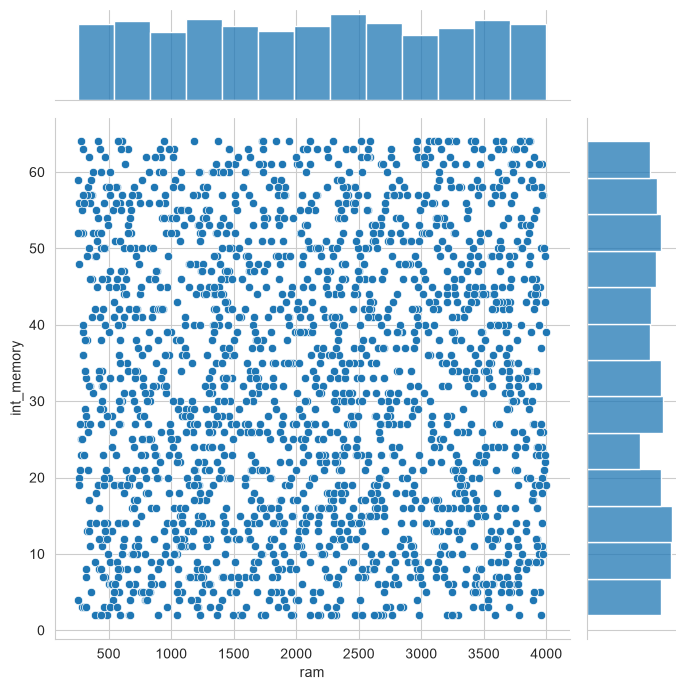

In [31]:
sns.jointplot(
    data=train_df,
    x="ram",
    y="int_memory",
    kind="scatter",
    height=7
)

plt.show()

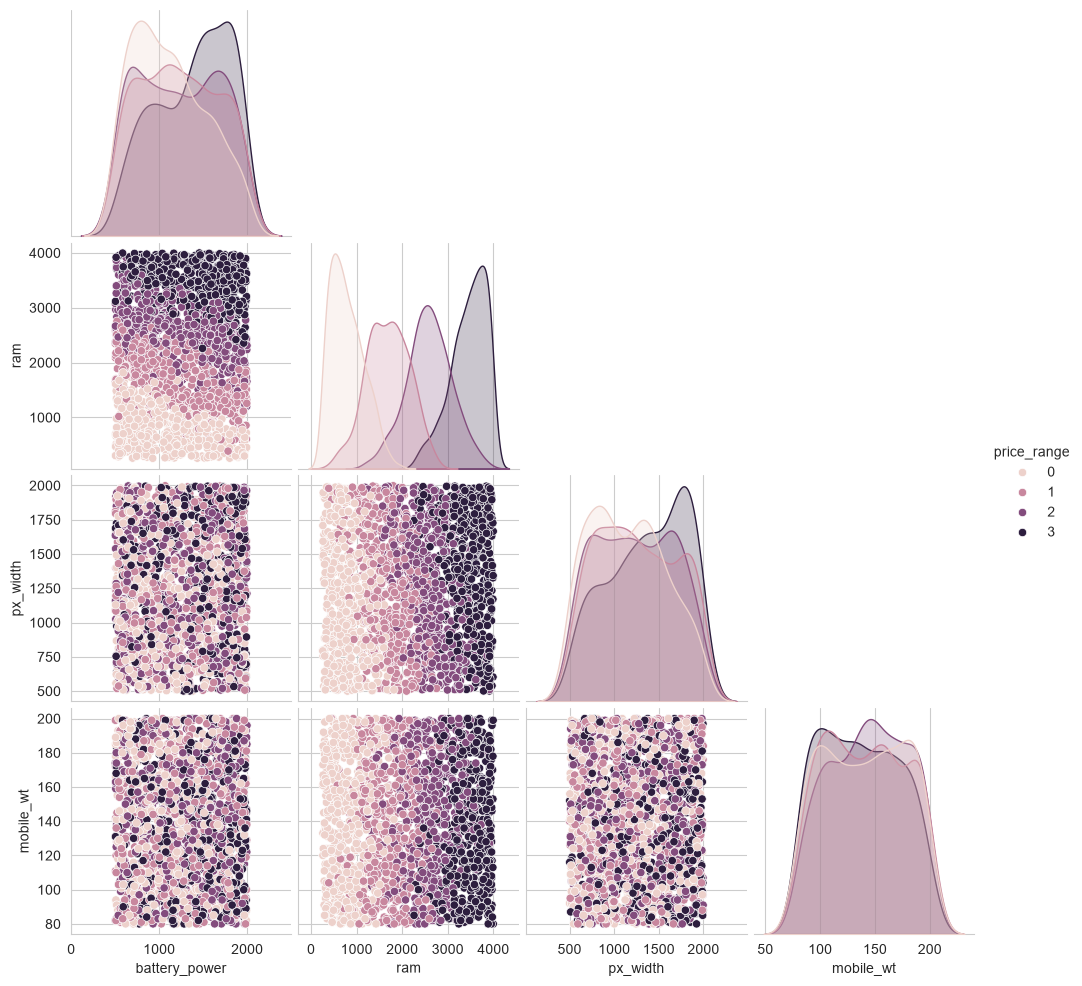

In [32]:
selected_features = [
    "battery_power",
    "ram",
    "px_width",
    "mobile_wt",
    "price_range"
]

sns.pairplot(
    train_df[selected_features],
    hue="price_range",
    corner=True
)

plt.show()

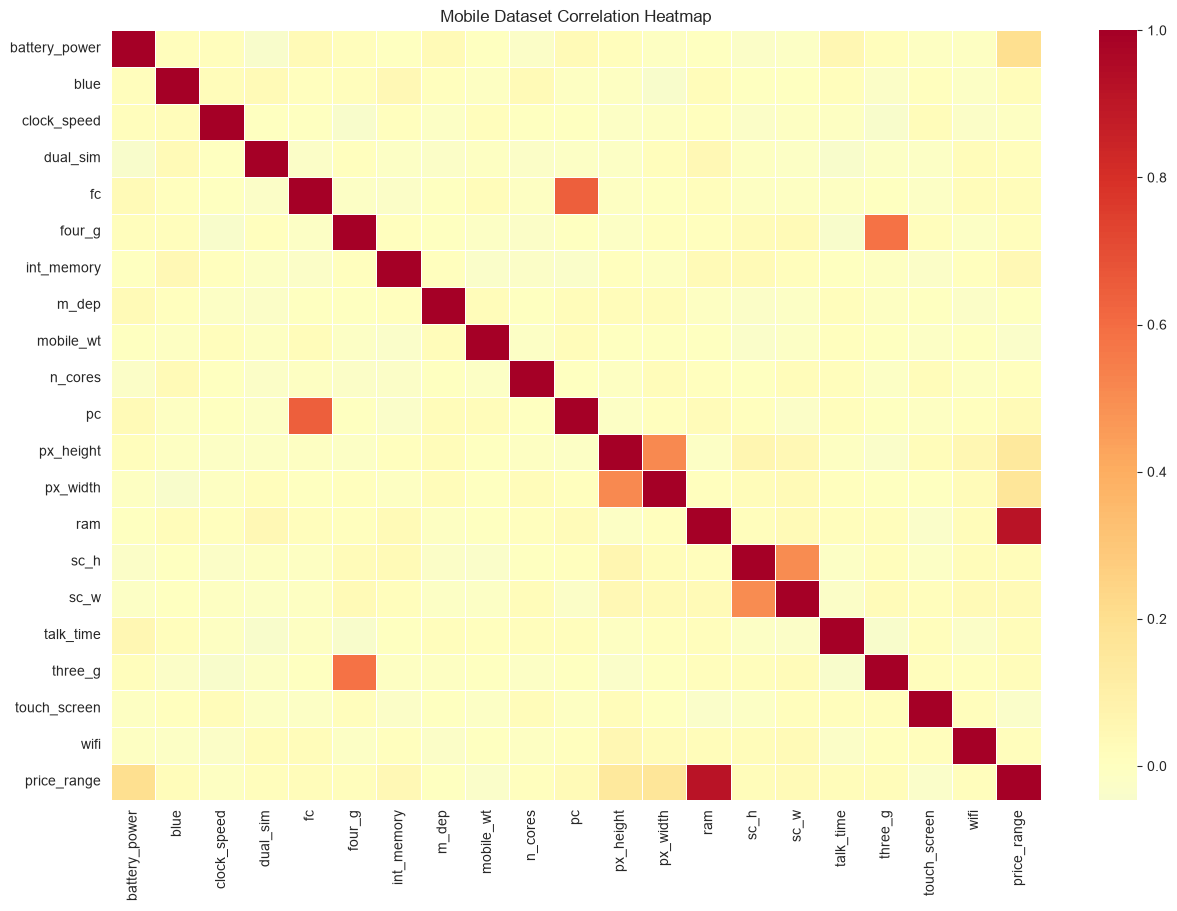

In [33]:
plt.figure(figsize=(15, 10))

sns.heatmap(
    train_df.corr(),
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5
)

plt.title("Mobile Dataset Correlation Heatmap")
plt.show()

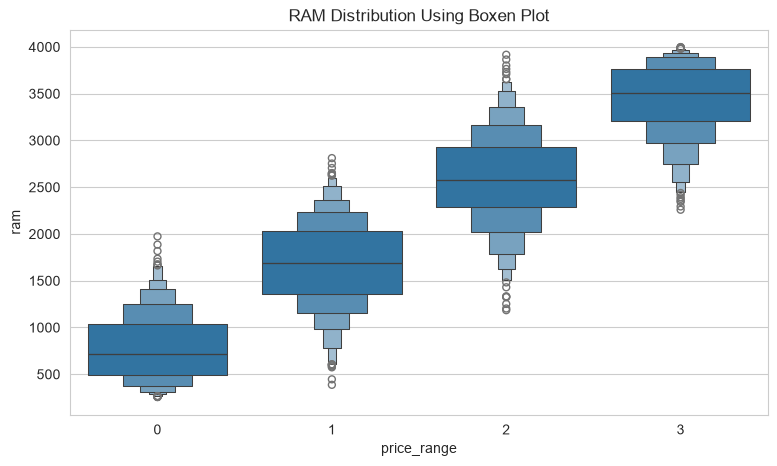

In [34]:
plt.figure(figsize=(9, 5))

sns.boxenplot(
    data=train_df,
    x="price_range",
    y="ram"
)

plt.title("RAM Distribution Using Boxen Plot")
plt.show()

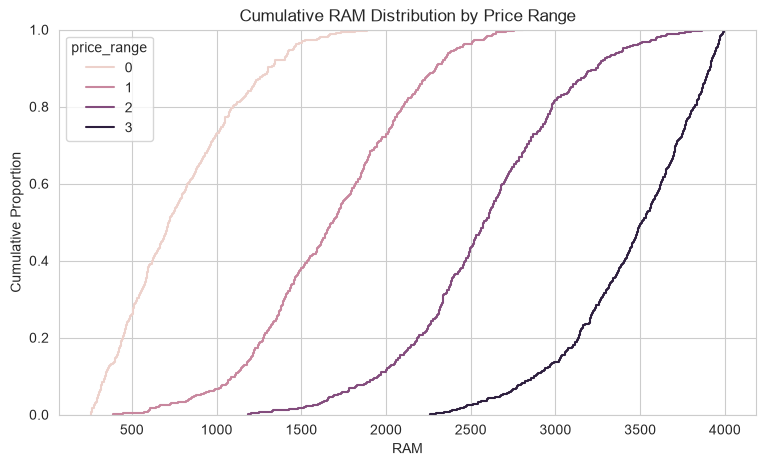

In [35]:
plt.figure(figsize=(9, 5))

sns.ecdfplot(
    data=train_df,
    x="ram",
    hue="price_range"
)

plt.title("Cumulative RAM Distribution by Price Range")
plt.xlabel("RAM")
plt.ylabel("Cumulative Proportion")

plt.show()

In [36]:
####Machine Learning Model Training

In [37]:
# Step 27: Find strongest positive correlation

strongest_feature = (
    price_correlation.drop("price_range").idxmax()
)

strongest_value = (
    price_correlation.drop("price_range").max()
)

print("Strongest positively correlated feature:", strongest_feature)
print("Correlation value:", round(strongest_value, 3))

Strongest positively correlated feature: ram
Correlation value: 0.917


In [38]:
# Step 1: Separate features and target

X = train_df.drop("price_range", axis=1)
y = train_df["price_range"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 20)
Target shape: (2000,)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1600, 20)
Testing data: (400, 20)


In [40]:
# Step 3: Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


D:\Mobile-Price-Range-Classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [41]:
# Step 4: Decision Tree

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [42]:
# Step 5: Random Forest

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [43]:
# Step 6: K-Nearest Neighbors

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

print("KNN trained successfully!")


KNN trained successfully!


In [44]:
# Step 7: Support Vector Machine

from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

svm_model.fit(X_train, y_train)

print("SVM trained successfully!")

SVM trained successfully!


In [45]:
# Step 8: Compare model accuracy

from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "KNN": knn_model,
    "SVM": svm_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  Accuracy
                SVM    0.8950
      Random Forest    0.8800
      Decision Tree    0.8300
Logistic Regression    0.6775
                KNN    0.5000


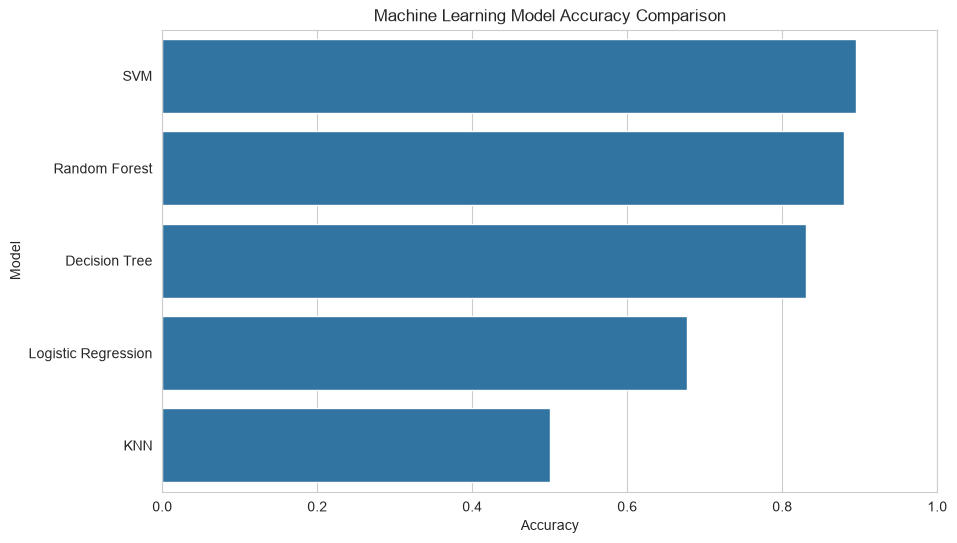

In [46]:
# Step 9: Model accuracy comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

In [47]:
# Step 10: Classification report for best model

from sklearn.metrics import classification_report

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Best Model: SVM
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       100
           1       0.87      0.87      0.87       100
           2       0.82      0.87      0.84       100
           3       0.94      0.90      0.92       100

    accuracy                           0.90       400
   macro avg       0.90      0.90      0.90       400
weighted avg       0.90      0.90      0.90       400



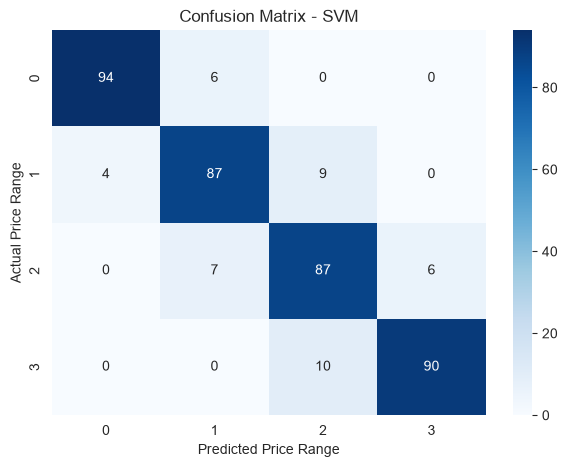

In [48]:
# Step 11: Confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Price Range")
plt.ylabel("Actual Price Range")

plt.show()

In [49]:
# Step 12: Save the best model

import joblib
from pathlib import Path

MODEL_DIR = Path("artifacts")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    best_model,
    MODEL_DIR / "best_model.pkl"
)

print("Best model saved successfully!")
print("Model:", best_model_name)

Best model saved successfully!
Model: SVM


In [50]:
# Step 13: Baseline model accuracy and AUC

from sklearn.metrics import accuracy_score, roc_auc_score

# Baseline predictions
baseline_predictions = logistic_model.predict(X_test)

# Predicted probabilities
baseline_probabilities = logistic_model.predict_proba(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

# Calculate multiclass AUC
baseline_auc = roc_auc_score(
    y_test,
    baseline_probabilities,
    multi_class="ovr",
    average="weighted"
)

print("Baseline Model: Logistic Regression")
print("Accuracy:", round(baseline_accuracy, 4))
print("AUC:", round(baseline_auc, 4))

Baseline Model: Logistic Regression
Accuracy: 0.6775
AUC: 0.8977


In [51]:
# Test Dataset Analysis and Prediction

In [52]:
# Load test dataset

test_df = pd.read_csv(
    r"D:\Mobile-Price-Range-Classification\data\raw\test.csv"
)

print("Test dataset shape:", test_df.shape)

test_df.head()

Test dataset shape: (1000, 21)


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,3,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,5,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,3,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,8,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,6,18,749,810,1773,15,8,7,1,0,1


In [53]:
# Check test dataset information

test_df.info()

print("Missing values:", test_df.isnull().sum().sum())
print("Duplicate rows:", test_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             1000 non-null   int64  
 1   battery_power  1000 non-null   int64  
 2   blue           1000 non-null   int64  
 3   clock_speed    1000 non-null   float64
 4   dual_sim       1000 non-null   int64  
 5   fc             1000 non-null   int64  
 6   four_g         1000 non-null   int64  
 7   int_memory     1000 non-null   int64  
 8   m_dep          1000 non-null   float64
 9   mobile_wt      1000 non-null   int64  
 10  n_cores        1000 non-null   int64  
 11  pc             1000 non-null   int64  
 12  px_height      1000 non-null   int64  
 13  px_width       1000 non-null   int64  
 14  ram            1000 non-null   int64  
 15  sc_h           1000 non-null   int64  
 16  sc_w           1000 non-null   int64  
 17  talk_time      1000 non-null   int64  
 18  three_g        1000 

In [54]:
# Check test dataset information

test_df.info()

print("Missing values:", test_df.isnull().sum().sum())
print("Duplicate rows:", test_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             1000 non-null   int64  
 1   battery_power  1000 non-null   int64  
 2   blue           1000 non-null   int64  
 3   clock_speed    1000 non-null   float64
 4   dual_sim       1000 non-null   int64  
 5   fc             1000 non-null   int64  
 6   four_g         1000 non-null   int64  
 7   int_memory     1000 non-null   int64  
 8   m_dep          1000 non-null   float64
 9   mobile_wt      1000 non-null   int64  
 10  n_cores        1000 non-null   int64  
 11  pc             1000 non-null   int64  
 12  px_height      1000 non-null   int64  
 13  px_width       1000 non-null   int64  
 14  ram            1000 non-null   int64  
 15  sc_h           1000 non-null   int64  
 16  sc_w           1000 non-null   int64  
 17  talk_time      1000 non-null   int64  
 18  three_g        1000 

In [55]:
# Separate ID and input features

test_ids = test_df["id"]

X_final_test = test_df.drop("id", axis=1)

print("Test features:", X_final_test.shape)

Test features: (1000, 20)


In [56]:
# Step 19: Predict mobile price categories

final_test_predictions = best_model.predict(X_final_test)

print("Predictions generated successfully!")
print("Total predictions:", len(final_test_predictions))

print("First 20 predictions:")
print(final_test_predictions[:20])

Predictions generated successfully!
Total predictions: 1000
First 20 predictions:
[3 3 2 3 1 3 3 1 3 0 3 3 0 0 2 0 2 1 3 1]


In [57]:
# Step 20: Create prediction DataFrame

submission = pd.DataFrame({
    "id": test_ids,
    "price_range": final_test_predictions
})

submission.head(10)

,id,price_range
0,1,3
1,2,3
2,3,2
3,4,3
4,5,1
5,6,3
6,7,3
7,8,1
8,9,3
9,10,0


In [58]:
# Step 21: Count predictions in each category

print(submission["price_range"].value_counts().sort_index())

price_range
0    248
1    249
2    261
3    242
Name: count, dtype: int64


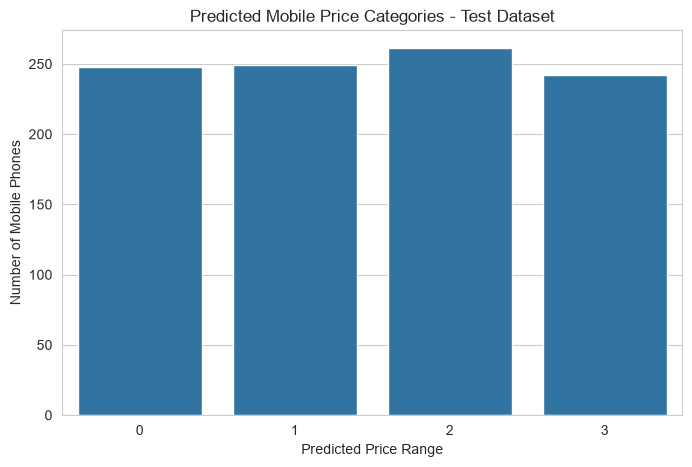

In [59]:
# Step 22: Visualize predicted price categories

plt.figure(figsize=(8, 5))

sns.countplot(
    data=submission,
    x="price_range"
)

plt.title("Predicted Mobile Price Categories - Test Dataset")
plt.xlabel("Predicted Price Range")
plt.ylabel("Number of Mobile Phones")

plt.show()

In [60]:
# Step 23: Save predictions

submission.to_csv(
    "mobile_price_predictions.csv",
    index=False
)

print("Prediction file saved successfully!")

Prediction file saved successfully!


In [61]:
from pathlib import Path

OUTPUT_PATH = Path.cwd().parent / "mobile_price_predictions.csv"

submission.to_csv(OUTPUT_PATH, index=False)

print("File saved at:", OUTPUT_PATH)

File saved at: D:\Mobile-Price-Range-Classification\notebooks\mobile_price_predictions.csv


In [62]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
D:\Mobile-Price-Range-Classification\notebooks\01_eda.ipynb


In [63]:
# Step 30: Baseline model evaluation

from sklearn.metrics import accuracy_score, roc_auc_score

baseline_predictions = logistic_model.predict(X_test)
baseline_probabilities = logistic_model.predict_proba(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_auc = roc_auc_score(
    y_test,
    baseline_probabilities,
    multi_class="ovr",
    average="weighted"
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline AUC:", round(baseline_auc, 4))

Baseline Accuracy: 0.6775
Baseline AUC: 0.8977


# Exploratory Data Analysis - Key Findings

## 1. Dataset Overview
The training dataset contains 2,000 records and 21 columns.
It includes 20 input features and one target variable called price_range.

## 2. Data Quality
Missing values and duplicate records were checked to understand
the quality of the dataset.

## 3. Price Distribution
The dataset contains four mobile price categories:
0, 1, 2 and 3.

## 4. Important Features
RAM, battery power, internal memory, pixel width and mobile weight
were explored to understand their relationship with mobile price range.

## 5. Correlation Analysis
A correlation heatmap was created to identify relationships
between numerical features and the target variable.

## 6. Machine Learning
Five classification algorithms were trained and compared:
Logistic Regression, Decision Tree, Random Forest, KNN and SVM.

## 7. Final Prediction
The selected model was used to predict price categories
for 1,000 unseen records from test.csv.